# Synthetic data

**On real data you can't tell a bad forecast from bad luck. On a series you generated yourself you can, because you know the best forecast anyone could have made.**

This chapter builds `Scenario`, the recipe for a test series: a kind of series, its settings, how many steps of history and how many steps to forecast. Each call to `generate(seed)` draws one case: the history the model sees, what actually happened next, and the **answer key**, the best forecast a forecaster that knows the true recipe could make from the same history. We know the answer key because we wrote the recipe.

Below we put one series' history, what actually happened and its answer key in one picture, and see why even the answer key misses what happened. Then we look at what the model receives and what stays with the evaluator, meet the six kinds of series behind eight of the ten rows of the [scorecard](13_scorecard.ipynb), and add measurement noise, which hides where a series is now.

**Development notebook.** Expand the collapsed cells to edit the code, then restart the kernel and Run All ([build workflow](README.md#develop-the-package-here)).

In [1]:
#| default_exp scenarios

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110, 'font.size': 11,
                     'figure.facecolor': 'white', 'axes.facecolor': 'white',
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})
pd.set_option('display.max_colwidth', None)
BLUE = '#0000CC'


def draw_case(ax, case, title, last=48):
    # Gray dots for the data, a thin line and a light band for the answer key.
    history = case.task.context.iloc[-last:, 0]
    low, high = case.reference.quantile((.1, .9))[:, 0].T
    ax.scatter(history.index, history, s=10, color='0.65', label='History')
    ax.scatter(case.observed.index, case.observed.iloc[:, 0], s=16, color='0.3',
               label='What actually happened')
    ax.fill_between(case.reference.index, low, high, color='0.9', lw=0, zorder=0,
                    label='Answer key, 80% range')
    ax.plot(case.reference.index, case.reference.mean[:, 0], color='0.2', lw=0.9, label='Answer key')
    ax.axvline(case.task.future_index[0] - 0.5, color=BLUE, ls='--', lw=0.9)
    ax.set(title=title, xlabel='Time step')

## Build the recipes

The collapsed cells write two modules: `timegym.scenarios`, with the `Scenario` recipe, its plain names and the five classic recipes, and `timegym.data.synthetic`, the older import path for those recipes, kept until TimeGym 2.0.

### Imports and default settings

Every kind of series has a default for each setting, so `Scenario('ar1')` works as it is, and the settings you pass replace the defaults. The case, the task and the answer key that a recipe returns are defined in [08 · Forecast contracts](08_forecast_contracts.ipynb).

In [3]:
#| export scenarios
from __future__ import annotations

from dataclasses import dataclass, field
from typing import Any

import numpy as np
import pandas as pd

from timegym.contracts import Case, ForecastTask, Reference, MANIFEST_SCHEMA_VERSION
from timegym._internal import _real_array
from timegym._process_common import _correlation
from timegym.processes import PROCESS_KINDS, resolve_process, _generate_resolved_process, _process_label

__all__ = ["Case", "CORE_KINDS", "scenario_label", "Scenario"]


In [4]:
#| export scenarios
_DEFAULTS = {
    "white_noise": {"mean": 0.0, "sigma": 1.0},
    "trend": {"intercept": 0.0, "slope": 0.1, "sigma": 1.0},
    "seasonal": {"mean": 0.0, "amplitude": 1.0, "period": 12.0, "sigma": 1.0},
    "ar1": {"mean": 0.0, "phi": 0.8, "sigma": 1.0},
    "random_walk": {"intercept": 0.0, "drift": 0.0, "sigma": 1.0},
    "ar2": {"mean": 0.0, "phi1": 1.0, "phi2": -0.5, "sigma": 1.0},
}

# The five families of the original suite; ``default_scenarios`` draws these.
CORE_KINDS = ("white_noise", "trend", "seasonal", "ar1", "random_walk")
# Families whose shocks persist. They also accept optional measurement
# ``noise``: independent Gaussian error added to each observation, which
# hides the process's current state from the forecaster.
_MEASURED_KINDS = ("ar1", "ar2", "random_walk")
_SCALAR_PARAMETERS = {"phi", "phi1", "phi2", "period"}

In [5]:
#| export scenarios
from timegym._internal import positive_int

In [6]:
#| export scenarios
from timegym._internal import nonnegative_int

### Plain names for plots (`scenario_label`)

The `kind` string, such as `'ar1'` or `'random_walk'`, stays fixed for code and saved reports. `scenario_label` turns it into the name a plot prints, says whether a random walk has drift, and adds "+ measurement noise" when there is some.

In [7]:
#| export scenarios
def scenario_label(kind: str, parameters=None, *, target_index=None) -> str:
    """Describe a process without replacing its stable machine-readable kind.

    Parameters may be raw scalar/vector values or a resolved case manifest's
    parameter dictionary. A target index selects its drift for a plot facet;
    otherwise a mixed zero/nonzero drift vector is described at case level.
    Nonzero measurement ``noise`` is named in the label. This formats labels
    rather than validating a full generator specification. Unknown custom
    kinds are returned unchanged.
    """
    if kind in PROCESS_KINDS:
        return _process_label(kind, {} if parameters is None else parameters, target_index=target_index)
    parameters = {} if parameters is None else parameters
    labels = {
        "white_noise": "Gaussian white noise (fixed mean)",
        "trend": "Linear trend + white noise",
        "seasonal": "Seasonality + white noise",
        "ar1": "Stationary AR(1)",
        "ar2": "Stationary AR(2)",
    }
    if kind == "random_walk":
        drift = _real_array(parameters.get("drift", 0.0), "drift")
        if drift.ndim > 1 or drift.size == 0 or not np.isfinite(drift).all():
            raise ValueError("drift must be a finite scalar or a nonempty vector")
        if target_index is not None:
            target_index = nonnegative_int(target_index, 'target_index')
            if drift.ndim == 1:
                drift = drift[target_index]
        nonzero = drift != 0
        if not np.any(nonzero):
            label = "Random walk without drift"
        elif np.all(nonzero):
            label = "Random walk with drift"
        else:
            label = "Random walk (mixed drift across targets)"
    else:
        label = labels.get(kind, kind)
    if kind in _MEASURED_KINDS and np.any(np.asarray(parameters.get("noise", 0.0), dtype=float) != 0):
        label += " + measurement noise"
    return label

### Finding a level hidden by noise

In a random walk or an AR process, shocks carry forward, so the best forecast starts from where the series is now. Add measurement noise, a fresh error on every observation, and that position is hidden. The Kalman filter weighs the noisy history to estimate it, and with the true settings it gives the exact answer key for these recipes.

In [8]:
#| export scenarios
def _kalman_forecast(observations, transition, offset, innovation, measurement,
                     initial_mean, initial_covariance, horizon):
    """Exact Gaussian forecast for a linear state observed with noise.

    The state follows ``s_t = offset + transition @ s_{t-1} + shock`` and each
    observation is the state's first ``d`` entries plus measurement error.
    Returns the conditional mean ``(horizon, d)``, the horizon-major joint
    covariance ``(horizon*d, horizon*d)`` and the final filtered state mean.
    The Joseph-form update with a pseudo-inverse stays valid when an
    observation is noise-free.
    """
    length, dimensions = observations.shape
    size = len(offset)
    loading = np.eye(dimensions, size)
    mean, cov = initial_mean.copy(), initial_covariance.copy()
    for t in range(length):
        if t:
            mean = offset + transition @ mean
            cov = transition @ cov @ transition.T + innovation
        gain = cov @ loading.T @ np.linalg.pinv(loading @ cov @ loading.T + measurement, hermitian=True)
        mean = mean + gain @ (observations[t] - loading @ mean)
        keep = np.eye(size) - gain @ loading
        cov = keep @ cov @ keep.T + gain @ measurement @ gain.T
        cov = (cov + cov.T) / 2
    filtered = mean.copy()
    means, state_covs = [], []
    for _ in range(horizon):
        mean = offset + transition @ mean
        cov = transition @ cov @ transition.T + innovation
        means.append(loading @ mean)
        state_covs.append(cov)
    joint = np.zeros((horizon * dimensions, horizon * dimensions))
    for i in range(horizon):
        cross = state_covs[i]
        for j in range(i, horizon):
            block = loading @ cross @ loading.T + (measurement if i == j else 0)
            joint[i * dimensions:(i + 1) * dimensions, j * dimensions:(j + 1) * dimensions] = block
            joint[j * dimensions:(j + 1) * dimensions, i * dimensions:(i + 1) * dimensions] = block.T
            cross = cross @ transition.T
    return np.array(means), (joint + joint.T) / 2, filtered

### The recipe (`Scenario`)

A `Scenario` holds the kind, its settings, the length of the history (`context_length`), the number of steps to forecast (`horizon`), the number of series (`n_targets`) and a default seed. It checks the settings as soon as it is created. `generate(seed)` draws one `Case` with its own random generator, so the same seed always gives the same case.

The answer key follows from the recipe. For noise around a level, a line or a cycle, it is that pattern. For AR(1) it starts from the last value and fades toward the average, and for AR(2) it finishes the current swing as it fades. For a random walk it stays at the last value, plus any drift. With measurement noise, the filter above provides it. The recipes of [14 · Controlled processes](14_controlled_processes.ipynb), with jumps, calm and stormy periods and hidden regimes, go through the same class.

In [9]:
#| export scenarios
@dataclass
class Scenario:
    """A fully specified known-parameter data-generating process.

    Vector-valued location/scale parameters are allowed, with one entry per
    target. ``phi``, ``phi1``, ``phi2`` and ``period`` are scalar.
    ``correlation`` is either an equicorrelation coefficient or a
    positive-semidefinite correlation matrix.

    AR(1) starts from its stationary distribution and requires ``abs(phi)<1``.
    AR(2) uses two lags, ``phi1`` and ``phi2``; with ``phi1**2 + 4*phi2 < 0``
    its shocks ring as irregular cycles. It also starts stationary.
    White noise fluctuates around a fixed mean; trend and seasonal processes
    add noise independently over time to a deterministic mean. Those shocks
    do not carry into future observations. A random walk instead accumulates
    shocks, starts at ``intercept`` at index zero, and has optional ``drift``
    (zero by default). Its variance grows with the forecast horizon. Targets
    may have correlated contemporaneous innovations in every family. Zero
    ``sigma`` gives a degenerate deterministic component. AR(1), AR(2) and
    random walks accept an optional measurement ``noise``: an independent
    Gaussian error with that standard deviation is added to each
    observation, so the process's current state is hidden; the reference is
    then the exact Kalman-filter conditional law. Parameters are exposed
    to the evaluator only; a model receives just ``case.task``. The
    composite, Merton, GARCH and hidden-regime processes also support joint
    targets, with explicit dependence laws and reference capabilities. These
    four controlled families snapshot resolved parameters at construction;
    create a new Scenario to change their parameters.
    """

    kind: str
    context_length: int = 120
    horizon: int = 12
    parameters: dict[str, Any] = field(default_factory=dict)
    n_targets: int = 1
    seed: int = 0

    def __post_init__(self) -> None:
        if self.kind in PROCESS_KINDS:
            self._resolved_parameters = self._resolve_process()
        else:
            self._resolve()

    def _resolve_process(self):
        return resolve_process(self.kind, self.parameters, self.context_length,
                               self.horizon, self.n_targets, self.seed)

    @property
    def display_name(self) -> str:
        """Parameter-aware label; ``kind`` remains the stable scenario identifier."""
        if self.kind in PROCESS_KINDS:
            return _process_label(self.kind, self._resolved_parameters)
        parameters, _, _, _, _ = self._resolve()
        return scenario_label(self.kind, parameters)

    def _resolve(self) -> tuple[dict, np.ndarray, int, int, int]:
        if self.kind not in _DEFAULTS:
            raise ValueError(f"Unknown scenario {self.kind!r}; choose from {tuple(_DEFAULTS)}")
        length = positive_int(self.context_length, 'context_length')
        horizon = positive_int(self.horizon, 'horizon')
        dimensions = positive_int(self.n_targets, 'n_targets')
        nonnegative_int(self.seed, 'seed')
        if not isinstance(self.parameters, dict):
            raise TypeError("parameters must be a dictionary")
        optional = {"correlation"} | ({"noise"} if self.kind in _MEASURED_KINDS else set())
        unsupported = set(self.parameters) - set(_DEFAULTS[self.kind]) - optional
        if unsupported:
            raise ValueError(f"Unsupported parameters for {self.kind}: {sorted(unsupported)}")
        parameters = {**_DEFAULTS[self.kind], **self.parameters}
        correlation = _correlation(parameters.pop("correlation", 0.0), dimensions)
        resolved: dict[str, Any] = {}
        for name, raw in parameters.items():
            value = _real_array(raw, name)
            if not np.isfinite(value).all():
                raise ValueError(f"{name} must be finite")
            if name in _SCALAR_PARAMETERS:
                if value.ndim != 0:
                    raise ValueError(f"{name} must be scalar")
                resolved[name] = float(value)
            else:
                if value.ndim == 0:
                    value = np.full(dimensions, float(value))
                if value.shape != (dimensions,):
                    raise ValueError(f"{name} must be scalar or have one entry per target")
                resolved[name] = value
        if np.any(resolved["sigma"] < 0):
            raise ValueError("sigma must be nonnegative")
        if "noise" in resolved and np.any(resolved["noise"] < 0):
            raise ValueError("noise must be nonnegative")
        if self.kind == "ar2":
            phi1, phi2 = resolved["phi1"], resolved["phi2"]
            if not (phi1 + phi2 < 1 and phi2 - phi1 < 1 and abs(phi2) < 1):
                raise ValueError("Stationary ar2 requires phi1 + phi2 < 1, phi2 - phi1 < 1 and abs(phi2) < 1")
        if "phi" in resolved and not abs(resolved["phi"]) < 1:
            raise ValueError("Stationary ar1 requires abs(phi) < 1")
        if "period" in resolved and resolved["period"] <= 0:
            raise ValueError("period must be positive")
        return resolved, correlation, length, horizon, dimensions

    def generate(self, seed: int | None = None) -> Case:
        """Generate context and held-out observations without global RNG state."""
        if self.kind in PROCESS_KINDS:
            run_seed = nonnegative_int(self.seed if seed is None else seed, 'seed')
            return _generate_resolved_process(self.kind, self._resolved_parameters, self.context_length,
                                    self.horizon, self.n_targets, run_seed)
        p, correlation, length, horizon, dimensions = self._resolve()
        run_seed = nonnegative_int(self.seed if seed is None else seed, 'seed')
        rng = np.random.default_rng(run_seed)
        innovation_cov = correlation * np.outer(p["sigma"], p["sigma"])
        eigenvalues, eigenvectors = np.linalg.eigh(innovation_cov)
        factor = eigenvectors * np.sqrt(np.maximum(eigenvalues, 0.0))
        noise = rng.standard_normal((length + horizon, dimensions)) @ factor.T
        time = np.arange(length + horizon, dtype=float)[:, None]
        future_steps = np.arange(1, horizon + 1, dtype=float)[:, None]
        temporal_cov = np.eye(horizon)
        conditioning: dict[str, Any] = {
            "observed_through": length - 1,
            "known_generator_parameters": True,
            "future_observations_used": False,
        }

        if self.kind == "white_noise":
            signal = np.broadcast_to(p["mean"], noise.shape)
            values = signal + noise
            conditional_mean = signal[length:].copy()
        elif self.kind == "trend":
            signal = p["intercept"] + p["slope"] * time
            values = signal + noise
            conditional_mean = signal[length:].copy()
        elif self.kind == "seasonal":
            signal = p["mean"] + p["amplitude"] * np.sin(2 * np.pi * time / p["period"])
            values = signal + noise
            conditional_mean = signal[length:].copy()
        elif self.kind == "ar1":
            phi = p["phi"]
            values = np.empty_like(noise)
            values[0] = p["mean"] + noise[0] / np.sqrt(1.0 - phi * phi)
            for t in range(1, len(values)):
                values[t] = p["mean"] + phi * (values[t - 1] - p["mean"]) + noise[t]
            last = values[length - 1].copy()
            conditional_mean = p["mean"] + phi ** future_steps * (last - p["mean"])
            power = np.arange(horizon)[:, None] - np.arange(horizon)[None, :]
            loading = np.zeros((horizon, horizon))
            lower_triangle = power >= 0
            loading[lower_triangle] = phi ** power[lower_triangle]
            temporal_cov = loading @ loading.T
            conditioning["last_observed"] = last.tolist()
            conditioning["initialization"] = "stationary_distribution"
            state = (np.full((1, 1), phi), (1 - phi) * p["mean"], p["mean"],
                     innovation_cov / (1.0 - phi * phi))
        elif self.kind == "ar2":
            phi1, phi2 = p["phi1"], p["phi2"]
            # Stationary covariance of (x_t, x_{t-1}) for unit-variance shocks.
            gamma0 = (1 - phi2) / ((1 + phi2) * ((1 - phi2) ** 2 - phi1 ** 2))
            stationary = np.kron(np.array([[gamma0, phi1 * gamma0 / (1 - phi2)],
                                           [phi1 * gamma0 / (1 - phi2), gamma0]]), innovation_cov)
            low, vectors = np.linalg.eigh(stationary)
            start = np.tile(p["mean"], 2) + (vectors * np.sqrt(np.maximum(low, 0.0))) @ rng.standard_normal(2 * dimensions)
            values = np.empty_like(noise)
            values[0], previous = start[:dimensions], start[dimensions:]
            for t in range(1, len(values)):
                values[t] = (p["mean"] + phi1 * (values[t - 1] - p["mean"])
                             + phi2 * (previous - p["mean"]) + noise[t])
                previous = values[t - 1]
            conditioning["initialization"] = "stationary_distribution"
            identity = np.eye(dimensions)
            state = (np.block([[phi1 * identity, phi2 * identity], [identity, 0 * identity]]),
                     np.concatenate([(1 - phi1 - phi2) * p["mean"], np.zeros(dimensions)]),
                     np.tile(p["mean"], 2), stationary)
        else:  # random_walk
            values = np.empty_like(noise)
            values[0] = p["intercept"]
            for t in range(1, len(values)):
                values[t] = values[t - 1] + p["drift"] + noise[t]
            last = values[length - 1].copy()
            conditional_mean = last + future_steps * p["drift"]
            temporal_cov = np.minimum.outer(np.arange(1, horizon + 1), np.arange(1, horizon + 1))
            conditioning["last_observed"] = last.tolist()
            conditioning["initialization"] = "intercept_at_index_zero"
            state = (np.eye(1), p["drift"], p["intercept"], np.zeros((dimensions, dimensions)))

        covariance = None
        if self.kind == "ar2" or "noise" in p:
            # Measurement noise is drawn after the process shocks, so the hidden
            # path is the same at every noise level for a given seed.
            measurement = np.zeros(dimensions) if "noise" not in p else p["noise"]
            values = values + rng.standard_normal(values.shape) * measurement
            transition, offset, initial_mean, initial_cov = state
            if transition.shape[0] < len(offset):
                transition = np.kron(transition, np.eye(dimensions))
            state_innovation = np.zeros((len(offset), len(offset)))
            state_innovation[:dimensions, :dimensions] = innovation_cov
            conditional_mean, covariance, filtered = _kalman_forecast(
                values[:length], transition, offset, state_innovation, np.diag(measurement ** 2),
                np.broadcast_to(initial_mean, offset.shape).astype(float), initial_cov, horizon)
            conditioning.pop("last_observed", None)
            conditioning["filtered_state"] = filtered[:dimensions].tolist()
            conditioning["reference_method"] = "kalman_filter"

        names = ("y",) if dimensions == 1 else tuple(f"y{i}" for i in range(dimensions))
        context_index = pd.RangeIndex(length)
        future_index = pd.RangeIndex(length, length + horizon)
        context = pd.DataFrame(values[:length].copy(), index=context_index, columns=names)
        observed = pd.DataFrame(values[length:].copy(), index=future_index, columns=names)
        if covariance is None:
            covariance = np.kron(temporal_cov, innovation_cov)
        variance = np.diag(covariance).reshape(horizon, dimensions).copy()
        resolved_parameters = {name: value.tolist() if isinstance(value, np.ndarray) else value for name, value in p.items()}
        resolved_parameters["correlation"] = correlation.tolist()
        manifest = {
            "schema_version": MANIFEST_SCHEMA_VERSION,
            "kind": self.kind,
            "context_length": length,
            "horizon": horizon,
            "n_targets": dimensions,
            "target_names": list(names),
            "seed": run_seed,
            "parameters": resolved_parameters,
            "reference_kind": "analytic_conditional",
            "conditioning": conditioning.copy(),
            "array_order": "horizon_major_C",
        }
        reference = Reference(
            mean=conditional_mean,
            variance=variance,
            covariance=covariance,
            index=future_index.copy(),
            target_names=names,
            conditioning=conditioning,
        )
        return Case(ForecastTask(context, future_index), observed, reference, manifest)

### The five classic recipes (`default_scenarios`)

`default_scenarios` returns a fresh `Scenario` for each of the five classic kinds, with default settings. `timegym.data.synthetic` still imports it from `timegym.scenarios` under its older path until TimeGym 2.0. That import brings back the installed `Scenario`, so the two small cells around it keep this chapter's version for the examples.

In [10]:
# The import below brings back the installed Scenario; keep this chapter's for the examples.
_notebook_scenario_types = (Case, Scenario)

In [11]:
#| export data.synthetic
from timegym.contracts import Reference
from timegym.scenarios import CORE_KINDS, Case, Scenario, default_scenarios

__all__ = ["default_scenarios"]

In [12]:
#| export scenarios
def default_scenarios(context_length=120, horizon=12, *, n_targets=1, seed=0):
    """Return fresh specifications for the five core families.

    Call ``generate`` on each specification to draw a case. The same supplied
    seed is recorded in each specification. Use independent replicate seeds
    when aggregating experimental results.
    """
    return [
        Scenario(kind, context_length=context_length, horizon=horizon, n_targets=n_targets, seed=seed)
        for kind in CORE_KINDS
    ]

In [13]:
# The examples use this chapter's Scenario, not the installed copy imported above.
Case, Scenario = _notebook_scenario_types
assert Scenario.__module__ == __name__
assert Case.__module__ == "timegym.contracts"
assert type(default_scenarios()[0]) is Scenario  # default_scenarios builds this chapter's Scenario

## One series and its answer key

Mean reversion (AR(1)): each step keeps 0.85 of the gap between the series and its long-run level, 0, and adds a fresh shock. We draw 120 steps of history and 24 steps to forecast. The gray band holds 80% of the futures this recipe could produce from this history.

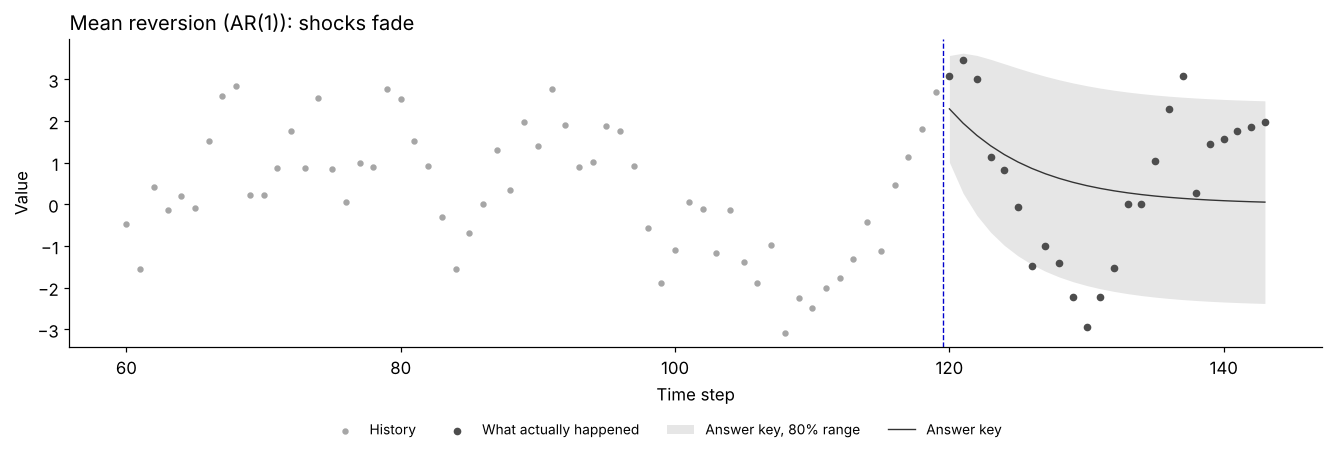

The history ends at 2.70. The answer key starts at 2.29 and ends at 0.05.
Its average squared error against what actually happened is 3.17, and 19 of the 24 values fall inside its 80% band.


In [14]:
phi = .85
recipe = Scenario('ar1', context_length=120, horizon=24, parameters={'phi': phi, 'sigma': 1.})
case = recipe.generate(seed=0)

fig, ax = plt.subplots(figsize=(12, 4), layout='constrained')
draw_case(ax, case, 'Mean reversion (AR(1)): shocks fade', last=60)
ax.set_ylabel('Value')
fig.legend(loc='outside lower center', ncol=4, fontsize=9)
plt.show()

last, answer_key, happened = case.task.context['y'].iloc[-1], case.reference.mean[:, 0], case.observed['y']
np.testing.assert_allclose(answer_key, phi ** np.arange(1, 25) * last)  # phi of the gap, step after step
low, high = case.reference.quantile((.1, .9))[:, 0].T
miss = float(((happened - answer_key) ** 2).mean())
inside = int(((happened >= low) & (happened <= high)).sum())
print(f'The history ends at {last:.2f}. The answer key starts at {answer_key[0]:.2f} and ends at {answer_key[-1]:.2f}.')
print(f'Its average squared error against what actually happened is {miss:.2f}, '
      f'and {inside} of the {len(happened)} values fall inside its 80% band.')

The history ends well above the long-run level, so the answer key starts at 0.85 × 2.70 = 2.29 and falls toward 0: that is the forecast someone who knew the recipe would make. Its band widens over the first few steps, as fresh shocks pile up, then stops widening as the old ones fade.

What actually happened rose above 3, fell to almost -3 around step 130 and climbed back to about 2. Those swings came from new shocks that nothing in the history could reveal, so the answer key missed them too, by an average squared error of 3.17, though 19 of the 24 values, about the 80% it promises, stayed inside its band. Is 3.17 bad luck, or the best anyone can do? Draw the same recipe 500 times:

In [15]:
misses = [float(((draw.observed.to_numpy() - draw.reference.mean) ** 2).mean())
          for draw in (recipe.generate(seed=seed) for seed in range(500))]
floor = float(case.reference.variance.mean())
assert abs(np.mean(misses) / floor - 1) < 0.1  # on average, the answer key misses by its own variance
print(f"Over 500 draws, the answer key's average squared error against what actually happened is "
      f'{np.mean(misses):.2f}. Its own variance, averaged over the 24 steps, is {floor:.2f}.')

Over 500 draws, the answer key's average squared error against what actually happened is 3.18. Its own variance, averaged over the 24 steps, is 3.21.


Over 500 draws the answer key's average squared error is 3.18, close to the 3.21 its own variance predicts: the answer key also knows how far off it will be. No forecaster can do better on average, because what is left is shocks that hadn't happened yet. That is why TimeGym scores a forecast by its error against the answer key, and doesn't rely on its error against what actually happened: the second includes this floor, which no model can remove.

## What the model sees, and what stays with the evaluator

`generate` returns a `Case`. Only part of it reaches the model:

In [16]:
context, dates = case.task.context, case.task.future_index
parts = pd.DataFrame([
    ('History', 'case.task.context', f'{len(context)} values, steps {context.index[0]} to {context.index[-1]}', 'the model'),
    ('Dates to forecast', 'case.task.future_index', f'steps {dates[0]} to {dates[-1]}', 'the model'),
    ('What actually happened', 'case.observed', f'{len(case.observed)} values, one per date', 'the evaluator'),
    ('Answer key', 'case.reference', 'mean, variance and covariance for those dates', 'the evaluator'),
    ('Recipe', 'case.manifest', f"kind {case.manifest['kind']!r}, its settings, seed {case.manifest['seed']}",
     'the evaluator'),
], columns=['Part', 'Where', 'Holds', 'Seen by']).set_index('Part')

assert recipe.generate(seed=0).task.context.equals(context)  # same recipe and seed, same series
parts

,Where,Holds,Seen by
Part,,,
History,case.task.context,"120 values, steps 0 to 119",the model
Dates to forecast,case.task.future_index,steps 120 to 143,the model
What actually happened,case.observed,"24 values, one per date",the evaluator
Answer key,case.reference,"mean, variance and covariance for those dates",the evaluator
Recipe,case.manifest,"kind 'ar1', its settings, seed 0",the evaluator


Only `case.task` reaches the model: the history and the dates to forecast. What actually happened and the answer key are used for scoring, and the recipe goes into the report so the case can be rebuilt later ([10 · Reports and replay](10_reports_and_replay.ipynb)). Each draw has its own random generator, seeded with `seed`, so the same recipe and seed always give the same case, whatever else your program does with random numbers.

## Six kinds of series

`default_scenarios` returns the five classic recipes with their default settings: noise around a constant level, noise around a straight line, noise around a repeating cycle, mean reversion (AR(1)) and a random walk. We add irregular cycles (AR(2)) and draw each kind once, with the same seed:

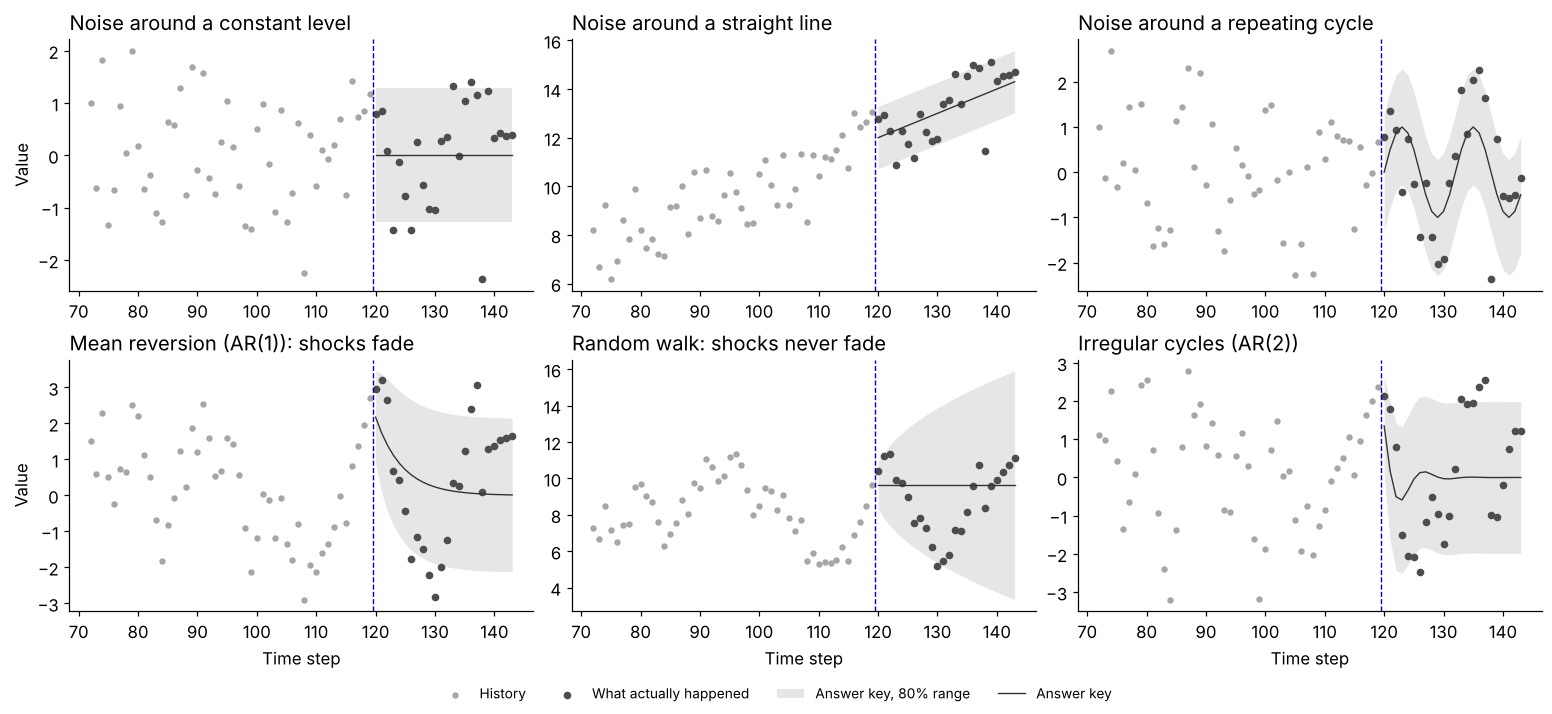

In [17]:
PLAIN_NAMES = {'white_noise': 'Noise around a constant level', 'trend': 'Noise around a straight line',
               'seasonal': 'Noise around a repeating cycle', 'ar1': 'Mean reversion (AR(1)): shocks fade',
               'random_walk': 'Random walk: shocks never fade', 'ar2': 'Irregular cycles (AR(2))'}
kinds = default_scenarios(context_length=120, horizon=24) + [Scenario('ar2', context_length=120, horizon=24)]

fig, axes = plt.subplots(2, 3, figsize=(14, 6.4), layout='constrained')
for ax, scenario in zip(axes.flat, kinds):
    draw_case(ax, scenario.generate(seed=0), PLAIN_NAMES[scenario.kind])
for ax in axes[0]:
    ax.set_xlabel('')
for ax in axes[:, 0]:
    ax.set_ylabel('Value')
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='outside lower center', ncol=4, fontsize=9)
plt.show()

Each answer key has the shape of its recipe. Around a constant level it is flat at 0. Around a straight line it is the line itself: the last few values sit above it, but that was noise, which doesn't carry over, so the answer key starts back on the line. Around a cycle it repeats the cycle, which is hard to see in the history because its swing (1) is no bigger than the noise. Mean reversion fades from the last value toward 0. The random walk's answer key stays at the last value while its range keeps widening, because shocks never fade. The AR(2) answer key finishes the current swing: it drops below 0, comes back and settles at 0 within about ten steps.

Here are each kind's default settings, the label plots print for it, and the rows of the scorecard built from it:

In [18]:
from timegym.grid import PATTERNS

scorecard_rows = {}
for pattern in PATTERNS.values():
    scorecard_rows.setdefault(pattern.build(0.5, 120, 24).kind, []).append(pattern.title)
assert scorecard_rows.keys() - PLAIN_NAMES.keys() == {'composite'}  # every other row uses a kind from this chapter

pd.DataFrame([{
    'Kind of series': PLAIN_NAMES[scenario.kind],
    'kind': scenario.kind,
    'Default settings': ', '.join(f'{name}={value:g}' for name, value in _DEFAULTS[scenario.kind].items()),
    'Label in plots': scenario.display_name,
    'Scorecard rows': '; '.join(scorecard_rows[scenario.kind]),
} for scenario in kinds]).set_index('Kind of series')

,kind,Default settings,Label in plots,Scorecard rows
Kind of series,,,,
Noise around a constant level,white_noise,"mean=0, sigma=1",Gaussian white noise (fixed mean),Pure noise; Noise around a fixed level
Noise around a straight line,trend,"intercept=0, slope=0.1, sigma=1",Linear trend + white noise,Straight-line trend
Noise around a repeating cycle,seasonal,"mean=0, amplitude=1, period=12, sigma=1",Seasonality + white noise,Repeating seasonal cycle
Mean reversion (AR(1)): shocks fade,ar1,"mean=0, phi=0.8, sigma=1",Stationary AR(1),Mean reversion (AR(1)): shocks fade
Random walk: shocks never fade,random_walk,"intercept=0, drift=0, sigma=1",Random walk without drift,Random walk: shocks never fade; Random walk with drift
Irregular cycles (AR(2)),ar2,"mean=0, phi1=1, phi2=-0.5, sigma=1",Stationary AR(2),Irregular cycles (AR(2))


Eight of the scorecard's ten rows come from these six kinds. The white-noise recipe makes both "Pure noise" and "Noise around a fixed level", and the random walk makes the rows with and without drift. The other two rows, "Trend + seasonal cycle" and "Sudden level shift", combine ingredients with chapter 14's `composite` recipe. The scorecard uses its own settings (its cycle swings by 3, for example), and on the mean reversion, irregular cycles and random walk rows its two noise levels are measurement noise, the subject of the last section.

A setting that a kind doesn't have, or a value it can't take, is refused when the recipe is made:

In [19]:
refused = []
for kind, settings in [('trend', {'drift': .2}), ('ar1', {'phi': 1.})]:
    try:
        Scenario(kind, parameters=settings)
    except ValueError as error:
        refused.append(kind)
        print(f'Scenario({kind!r}, parameters={settings}) is refused: {error}')
assert len(refused) == 2  # both are refused when the recipe is made

Scenario('trend', parameters={'drift': 0.2}) is refused: Unsupported parameters for trend: ['drift']
Scenario('ar1', parameters={'phi': 1.0}) is refused: Stationary ar1 requires abs(phi) < 1


A random walk's `drift` given to a straight line is refused instead of quietly ignored, which would test a different recipe from the one you meant. So is a misspelled setting. An AR(1) with weight 1 is refused because it never returns to a level: that is a random walk, and `random_walk` has the right answer key for it.

## Measurement noise hides where the series is now

Real measurements carry their own errors, like a sensor's noise or a survey's sampling error. Here is the same random walk drawn twice with the same seed: once as it is, and once seen through measurement noise with a standard deviation of 2, four times that of its steps (0.5). The blue crosses are the forecast that repeats the last observation.

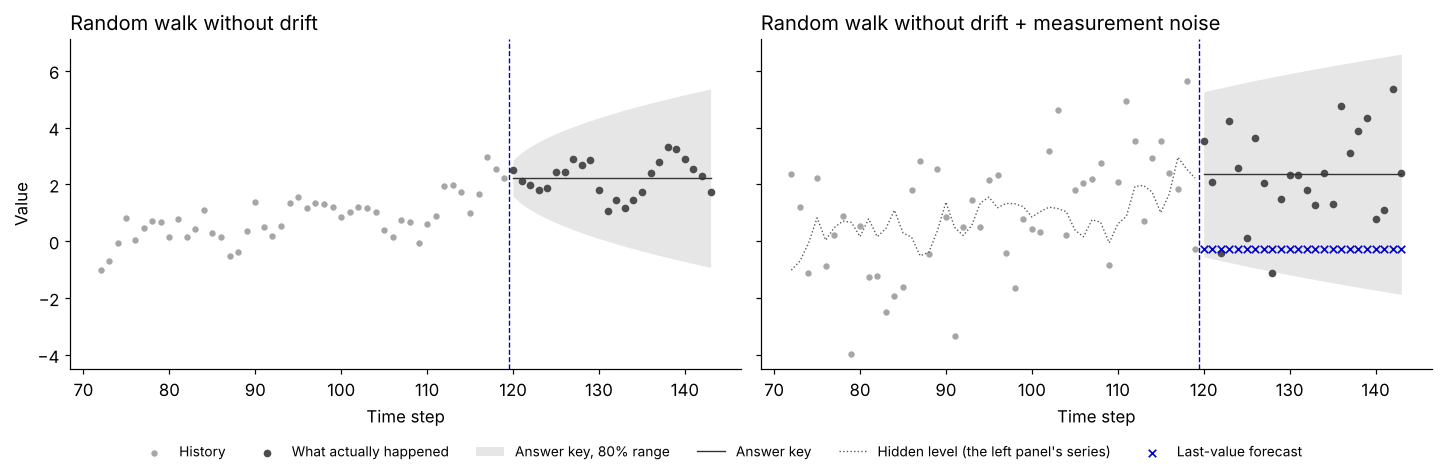

At the last step the hidden level is 2.22, the last observation is -0.28 and the answer key is 2.36.


Over 100 draws, the answer key is on average 0.76 from the hidden level, and the last observation 1.34.


In [20]:
clean = Scenario('random_walk', context_length=120, horizon=24, parameters={'sigma': .5})
noisy = Scenario('random_walk', context_length=120, horizon=24, parameters={'sigma': .5, 'noise': 2.})
clean_case, noisy_case = clean.generate(seed=11), noisy.generate(seed=11)
hidden = clean_case.task.context['y']  # same seed: the noisy series is this path plus measurement noise
last_seen = noisy_case.task.context['y'].iloc[-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True, layout='constrained')
draw_case(axes[0], clean_case, clean.display_name)
draw_case(axes[1], noisy_case, noisy.display_name)
axes[1].plot(hidden.index[-48:], hidden.iloc[-48:], color='0.35', lw=0.9, ls=':',
             label="Hidden level (the left panel's series)")
axes[1].scatter(noisy_case.task.future_index, np.full(24, last_seen), marker='x', s=24, linewidths=1.1,
                color=BLUE, label='Last-value forecast', zorder=4)
axes[0].set_ylabel('Value')
fig.legend(*axes[1].get_legend_handles_labels(), loc='outside lower center', ncol=6, fontsize=9)
plt.show()

np.testing.assert_allclose(clean_case.reference.mean[:, 0], hidden.iloc[-1])  # no noise: the last value is the answer key
print(f'At the last step the hidden level is {hidden.iloc[-1]:.2f}, the last observation is {last_seen:.2f} '
      f'and the answer key is {noisy_case.reference.mean[0, 0]:.2f}.')

gaps = []
for seed in range(100):
    level = clean.generate(seed=seed).task.context['y'].iloc[-1]
    draw = noisy.generate(seed=seed)
    gaps.append({'answer key': abs(draw.reference.mean[0, 0] - level),
                 'last observation': abs(draw.task.context['y'].iloc[-1] - level)})
gaps = pd.DataFrame(gaps).mean()
assert gaps['answer key'] < gaps['last observation']  # the answer key finds the hidden level better
print(f"Over 100 draws, the answer key is on average {gaps['answer key']:.2f} from the hidden level, "
      f"and the last observation {gaps['last observation']:.2f}.")

Without measurement noise, the last value is where the series is, and the answer key stays there, at 2.22. With noise, the last observation, -0.28, landed far below the hidden level of 2.22, and the last-value forecast copies that error into every step. The answer key, computed by the Kalman filter, weighs the recent observations instead and lands at 2.36, close to the hidden level. This draw is a striking one, but the pattern holds: over 100 draws the answer key is on average 0.76 from the hidden level, and the last observation 1.34. The answer key's range is also wider, because every future observation will carry its own measurement error.

**Limits.** The answer key knows the true settings, while a fitted model has to estimate them from the history, so even a well-built model stays a little behind it ([06 · Forecasting models](06_forecasting_models.ipynb) shows a fitted AR(1) doing so). All six kinds have Gaussian shocks, so a mean and a covariance describe their answer key completely. Jumps, calm and stormy periods, hidden regimes and a change of rules partway through a series are in [14 · Controlled processes](14_controlled_processes.ipynb). A random walk without drift can look like a trend over a short window, but its answer key stays flat: the look is chance, not a slope. Every recipe can also make several series at once (`n_targets`) whose shocks at the same step are correlated (`correlation`); [08 · Forecast contracts](08_forecast_contracts.ipynb) draws such a pair.

## Change one thing

- In the first example, set `phi` to 0.98: the answer key fades so slowly that it looks like a random walk's, and its range keeps widening.
- Draw `Scenario('random_walk', context_length=120, horizon=24, parameters={'drift': .1})` with `draw_case`, like the scorecard's "Random walk with drift" row: its answer key becomes a rising line that starts from the last value.
- Lower the measurement noise to 0.5, the scorecard's low noise. How far is the answer key from the last observation now?
- Draw the six kinds with `seed=1`: the random walk slides steadily down, as if it had a trend, while its answer key stays flat.

**Next:** [02 · Real data](02_real_data.ipynb), where there is no answer key, only what actually happened. [14 · Controlled processes](14_controlled_processes.ipynb) adds jumps, calm and stormy periods and hidden regimes to these recipes, and the [Quick start](../tutorials/01_quick_start.ipynb) scorecard is built from them.